In [1]:
import pandas as pd
import numpy as np
import re
!pip install pymorphy2
import pymorphy2


RANDOM_STATE = 42

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.5/55.5 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 60.6 MB/s eta 0:00:00
  Created wheel for docopt: filename=docopt-0.6.2-py2.py3-none-any.whl size=13706 sha256=b1a5d29cd1580cc13e3ae45a58e65eac7f79c614d3136568e92ea26fc7b21da6
  Stored in directory: /root/.cache/pip/wheels/fc/ab/d4/5da2067ac95b36618c629a5f93f809425700506f72c9732fac
Successfully built docopt


### Загрузка датасета

In [2]:
!unzip -o data.zip -d data

Archive:  data.zip
  inflating: data/3.csv              
  inflating: data/1.csv              
  inflating: data/2.csv              


#### 1. датасет 1

In [3]:
df = pd.read_csv('data/1.csv')
print(df.shape)
df.head(10)

(12420, 2)


,comment,toxic
0,верблюд дебил бл,1.0
1,хохол отдушина затюканый россиянин мол вон хох...,1.0
2,собака собачий смерть,1.0
3,страница обновить дебил оскорбление доказать ф...,1.0
4,убедить 6 страничный пдф скрипаль отравить рос...,1.0
5,стан являться эталон современный система здрав...,1.0
6,шапка ссылка инф текущий фильм марвести ссылка...,0.0
7,упад строить технология разворовать трещина по...,1.0
8,ебать разносить шизик,1.0
9,обосраться сидеть обтекать,1.0


In [4]:
LABELS_COUNT = 2

#### mini eda, detailed: https://github.com/hse-toxic/toxiccc/blob/eda-karnaukhov/eda/paper/paper_eda.ipynb

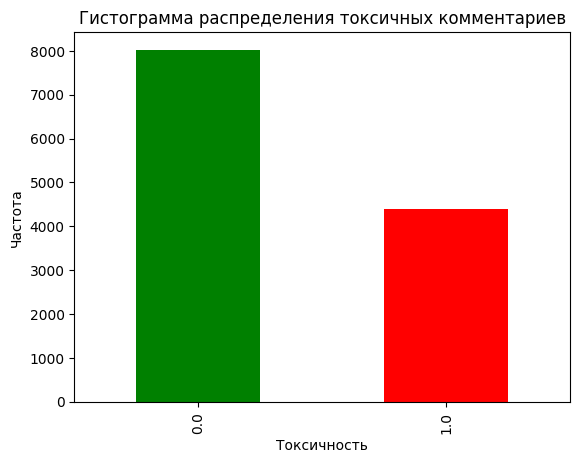

In [8]:
import matplotlib.pyplot as plt


df['toxic'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.xlabel('Токсичность')
plt.ylabel('Частота')
plt.title('Гистограмма распределения токсичных комментариев')
plt.show()

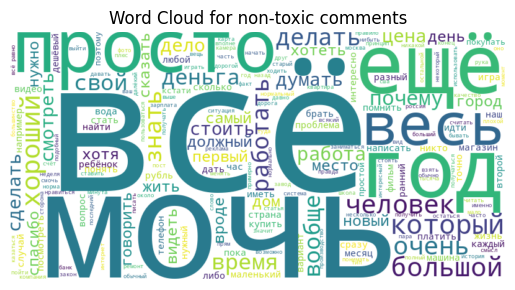

In [9]:
from wordcloud import WordCloud
from functools import reduce


wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] == 0.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for non-toxic comments')
plt.show()

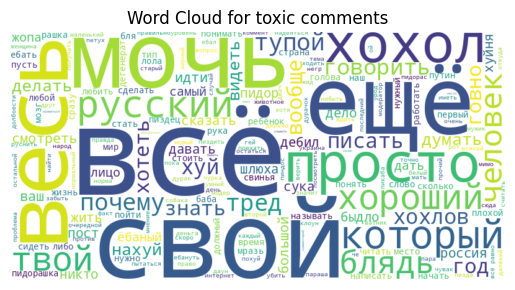

In [10]:
wordcloud_toxic = WordCloud(width=800, height=400, background_color='white').generate(' '.join(df[df['toxic'] == 1.0]['comment'].values))
plt.imshow(wordcloud_toxic, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for toxic comments')
plt.show()

#### train test split

In [11]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(df, test_size=0.33, random_state=RANDOM_STATE)
y_train = df_train['toxic']
y_true = df_test['toxic']

## Baseline

In [19]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import nltk


metrics = dict()

def get_metrics(y_true, y_pred, title=None):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(3, 3))

    ax = sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap=sns.color_palette("pastel", 5))
    ax.set_xlabel("Predicted", labelpad=20)
    ax.set_ylabel("Actual", labelpad=20)
    if title:
        ax.set_title(title)
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')

    print(f'accuracy:\t{accuracy}')
    print(f'precision:\t{precision}')
    print(f'recall:\t\t{recall}')
    print(f'f1:\t\t{f1}')

    if title:
        metrics[title] = dict()
        metrics[title]['accuracy'] = accuracy
        metrics[title]['precision'] = precision
        metrics[title]['recall'] = recall
        metrics[title]['f1'] = f1

### 1. Модель с константным предсказанием

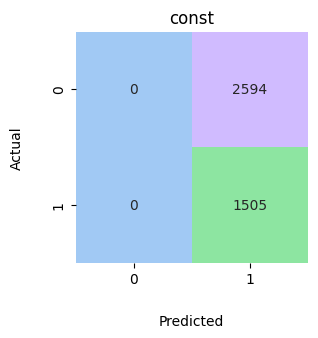

accuracy:	0.367162722615272
precision:	0.13480846487825918
recall:		0.367162722615272
f1:		0.19720909976302084


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [63]:
y_pred = np.full(y_true.shape, 1)
get_metrics(y_true, y_pred, 'const')

### 2. Модель со случайным предсказанием

In [14]:
class BaseLineModel():
    def __init__(self, predict_function):
        self.predict_function = predict_function

    def predict(self, X):
        return np.array(list(map(self.predict_function, X)))

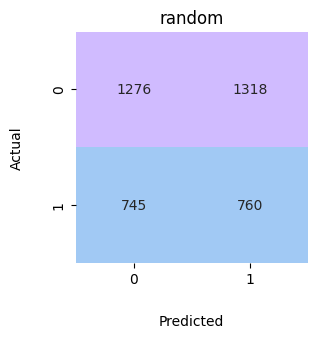

accuracy:	0.4967065137838497
precision:	0.5338395870923938
recall:		0.4967065137838497
f1:		0.5057057804232351


In [17]:
def random_prediction(comment):
    return np.random.randint(0, LABELS_COUNT)


random_model = BaseLineModel(random_prediction)
y_pred = random_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'random')

### 3. Lexicon-based

In [20]:
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


In [23]:
toxic_dict = dict()
for i in range(1, LABELS_COUNT):
    comments = " ".join(df_train[df_train['toxic'] == i]['comment'].tolist())
    comments_tokens = word_tokenize(comments)
    text = nltk.Text(comments_tokens)
    f_dist = FreqDist(text)
    toxic_dict[i] = set(map(lambda x: x[0], f_dist.most_common(20)))
print(toxic_dict)

{1: {'хороший', 'хохол', 'нахуй', 'твой', 'человек', 'который', 'весь', 'свой', 'тупой', 'ещё', 'хуй', 'хохлов', 'русский', 'просто', 'идти', 'почему', 'тред', 'всё', 'блядь', 'мочь'}}


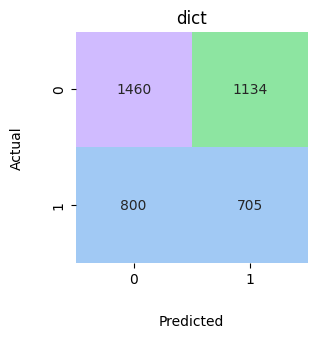

accuracy:	0.5281776042937302
precision:	0.5495797748594283
recall:		0.5281776042937302
f1:		0.5355076372812019


In [24]:
def dict_prediction(comment):
    for word in comment.split(' '):
        for label in toxic_dict:
            if word in toxic_dict[label]:
                return label
    return 0


dict_model = BaseLineModel(dict_prediction)
y_pred = dict_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'dict')

### 4. Rule-based

In [25]:
!pip install fkscore
import fkscore

In [26]:
df_test_copy = df_test.copy()
df_test_copy['fkscore'] = df_test_copy['comment'].apply(lambda comment: fkscore.fkscore(comment).score['readability'])
print(df_test_copy[df_test_copy['toxic'] == 0]['fkscore'].describe())
print()
print(df_test_copy[df_test_copy['toxic'] != 0]['fkscore'].describe())

count    2594.000000
mean      110.414308
std         7.580955
min        67.530000
25%       105.995000
50%       112.085000
75%       116.145000
max       121.220000
Name: fkscore, dtype: float64

count    1505.000000
mean      113.000002
std         6.398710
min        83.854000
25%       110.055000
50%       115.130000
75%       118.175000
max       121.220000
Name: fkscore, dtype: float64


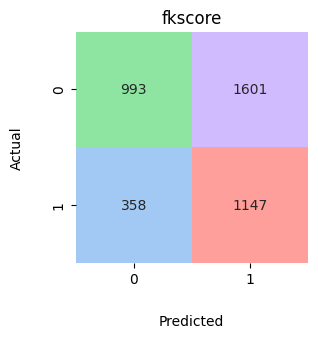

accuracy:	0.5220785557453037
precision:	0.618394114732501
recall:		0.5220785557453037
f1:		0.5166259263956418


In [30]:
def fkscore_prediction(comment):
    score = fkscore.fkscore(comment).score
    return score['readability'] > 110


fkscore_model = BaseLineModel(fkscore_prediction)
y_pred = fkscore_model.predict(df_test['comment'])
get_metrics(y_true, y_pred, 'fkscore')

### 5. BoW

#### 5.1 Logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer


vectorizer = CountVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

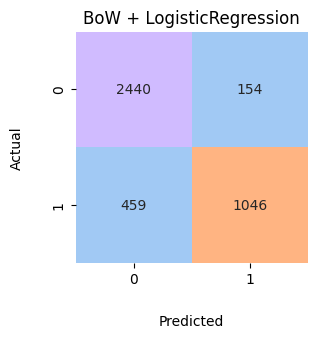

accuracy:	0.8504513295925835
precision:	0.8526833674703328
recall:		0.8504513295925835
f1:		0.8461720732715915


In [32]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + LogisticRegression')

#### 5.2 SVC

In [33]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

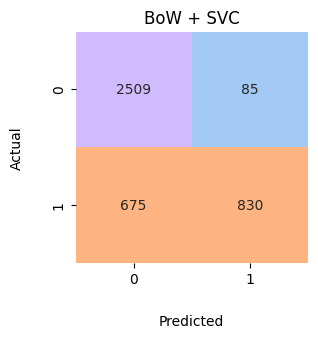

accuracy:	0.814588924127836
precision:	0.8317320747544622
recall:		0.814588924127836
f1:		0.801453458320676


In [34]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'BoW + SVC')

### 6. TF-IDF

#### 6.1 LogisticRegression

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer


vectorizer = TfidfVectorizer()
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
lr = LogisticRegression()
lr.fit(X_train, y_train)

LogisticRegression()

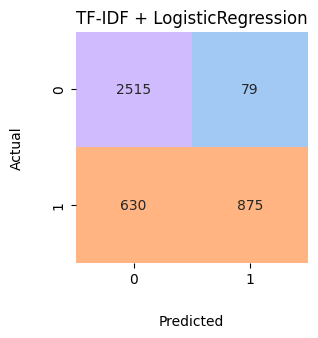

accuracy:	0.827030983166626
precision:	0.8428268641445619
recall:		0.827030983166626
f1:		0.8159553385969865


In [36]:
y_pred = lr.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + LogisticRegression')

#### 6.2 SVC

In [37]:
from sklearn import svm


clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

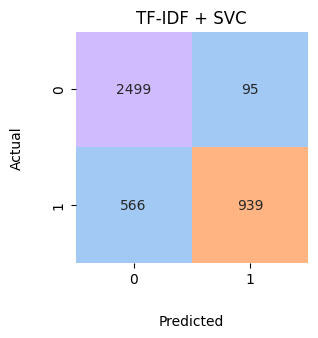

accuracy:	0.8387411563796048
precision:	0.849403218681233
recall:		0.8387411563796048
f1:		0.8304947135619883


In [38]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + SVC')

#### 6.3 GradientBoosting

In [39]:
from sklearn.ensemble import GradientBoostingClassifier


clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

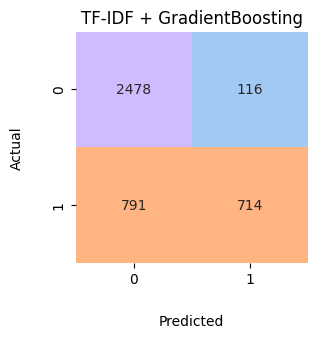

accuracy:	0.7787265186630885
precision:	0.7955580422191684
recall:		0.7787265186630885
f1:		0.7594812072335663


In [40]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'TF-IDF + GradientBoosting')

### 7. N-grams + Naive Byas

In [41]:
from sklearn.naive_bayes import MultinomialNB


vectorizer = CountVectorizer(ngram_range=(1, 2))
vectorizer.fit(df_train['comment'])
X_train = vectorizer.transform(df_train['comment'])
X_test = vectorizer.transform(df_test['comment'])
clf = MultinomialNB()
clf.fit(X_train, y_train)

MultinomialNB()

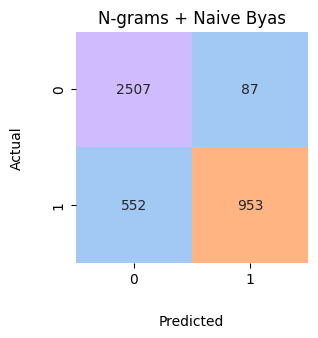

accuracy:	0.8441083191022201
precision:	0.8550892256585878
recall:		0.8441083191022201
f1:		0.8362783484356341


In [42]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'N-grams + Naive Byas')

### 8. Word2Vec

#### 8.1 LogisticRegression

In [43]:
from gensim.models import Word2Vec

VECTOR_SIZE = 100
sentences = [sentence.split() for sentence in df_train['comment']]
w2v_model = Word2Vec(sentences, vector_size=VECTOR_SIZE, window=5, min_count=5, workers=4)

In [44]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [w2v_model.wv[word] for word in words if word in w2v_model.wv]
    if len(words_vecs) == 0:
        return np.zeros(VECTOR_SIZE)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

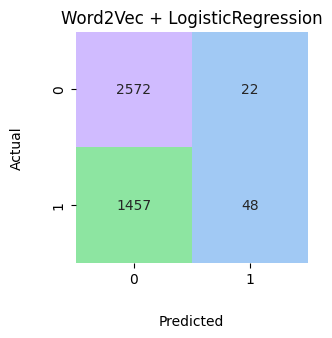

accuracy:	0.6391802878750915
precision:	0.6557541987460876
recall:		0.6391802878750915
f1:		0.5138961196078274


In [45]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + LogisticRegression')

#### 8.2 KNN

In [46]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

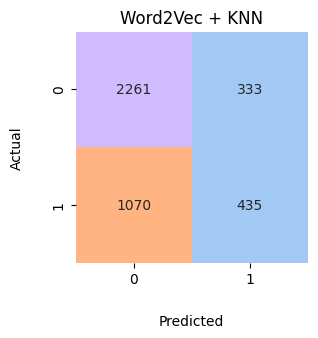

accuracy:	0.6577213954623079
precision:	0.637517474055607
recall:		0.6577213954623079
f1:		0.6235187086731724


In [47]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + KNN')

#### 8.3 SVC

In [48]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

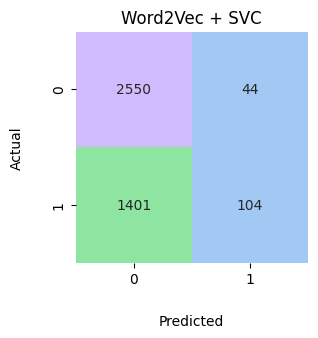

accuracy:	0.6474749939009514
precision:	0.666443356554451
recall:		0.6474749939009514
f1:		0.5393207103685823


In [49]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + SVC')

#### 8.4 GradientBoosting

In [50]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

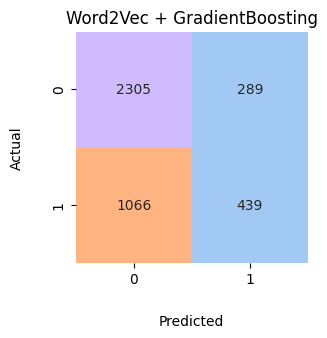

accuracy:	0.6694315686752866
precision:	0.6541244633837943
recall:		0.6694315686752866
f1:		0.6334487762069104


In [51]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'Word2Vec + GradientBoosting')

### 9. GloVe

#### 9.1 LogisticRegression

In [52]:
!pip install navec
!wget https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar

--2024-12-21 17:40:39--  https://storage.yandexcloud.net/natasha-navec/packs/navec_hudlit_v1_12B_500K_300d_100q.tar
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 53012480 (51M) [application/x-tar]
Saving to: ‘navec_hudlit_v1_12B_500K_300d_100q.tar’

navec_hudlit_v1_12B 100%[===================>]  50.56M  18.7MB/s    in 2.7s    

2024-12-21 17:40:42 (18.7 MB/s) - ‘navec_hudlit_v1_12B_500K_300d_100q.tar’ saved [53012480/53012480]



In [53]:
from navec import Navec

path = 'navec_hudlit_v1_12B_500K_300d_100q.tar'
navec = Navec.load(path)

In [54]:
def vectorize(comment):
    words = comment.split()
    words_vecs = [navec[word] for word in words if word in navec]
    if len(words_vecs) == 0:
        return np.zeros(300)
    words_vecs = np.array(words_vecs)
    return words_vecs.mean(axis=0)


X_train = np.array([vectorize(comment) for comment in df_train['comment']])
X_test = np.array([vectorize(comment) for comment in df_test['comment']])
clf = LogisticRegression()
clf.fit(X_train, y_train)

LogisticRegression()

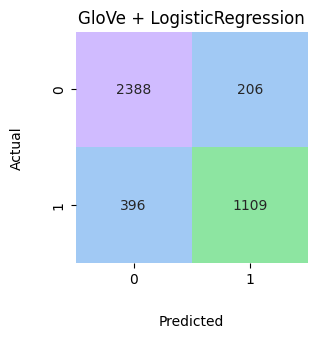

accuracy:	0.8531349109538912
precision:	0.8524668464293321
recall:		0.8531349109538912
f1:		0.8507816352437418


In [55]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + LogisticRegression')

#### 9.2 KNN

In [56]:
from sklearn.neighbors import KNeighborsClassifier


clf = KNeighborsClassifier(n_neighbors=3)
clf.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

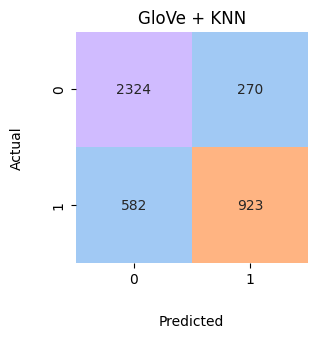

accuracy:	0.7921444254696267
precision:	0.790161987922256
recall:		0.7921444254696267
f1:		0.7860216297358091


In [57]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + KNN')

#### 9.3 SVC

In [58]:
clf = svm.SVC()
clf.fit(X_train, y_train)

SVC()

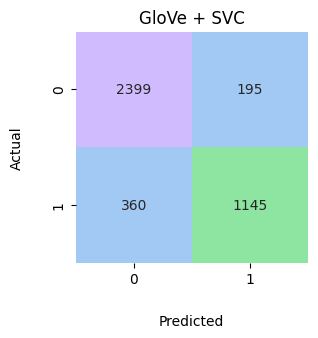

accuracy:	0.8646011222249329
precision:	0.86399569301255
recall:		0.8646011222249329
f1:		0.8627615492048969


In [59]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + SVC')

#### 9.4 GradientBoosting

In [60]:
clf = GradientBoostingClassifier(n_estimators=100, learning_rate=1.0, max_depth=1, random_state=RANDOM_STATE)
clf.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=1.0, max_depth=1, random_state=42)

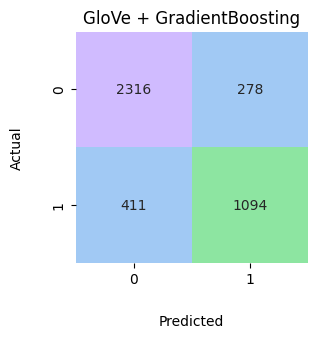

accuracy:	0.8319102220053671
precision:	0.8302259392336214
recall:		0.8319102220053671
f1:		0.8301256625174457


In [61]:
y_pred = clf.predict(X_test)
get_metrics(y_true, y_pred, 'GloVe + GradientBoosting')

### Вывод

In [64]:
metrics_df = pd.DataFrame(metrics).T
cols = metrics_df.columns.tolist()
cols = cols[-1:] + cols[:-1]
metrics_df = metrics_df[cols].sort_values(by=['f1'], ascending=False)
metrics_df

,f1,accuracy,precision,recall
GloVe + SVC,0.862762,0.864601,0.863996,0.864601
GloVe + LogisticRegression,0.850782,0.853135,0.852467,0.853135
BoW + LogisticRegression,0.846172,0.850451,0.852683,0.850451
N-grams + Naive Byas,0.836278,0.844108,0.855089,0.844108
TF-IDF + SVC,0.830495,0.838741,0.849403,0.838741
GloVe + GradientBoosting,0.830126,0.831910,0.830226,0.831910
TF-IDF + LogisticRegression,0.815955,0.827031,0.842827,0.827031
BoW + SVC,0.801453,0.814589,0.831732,0.814589
GloVe + KNN,0.786022,0.792144,0.790162,0.792144
TF-IDF + GradientBoosting,0.759481,0.778727,0.795558,0.778727


Из baseline моделей наилучшие результаты показали GloVe + SVC, GloVe + LogisticRegression и BoW + LogisticRegression. Стоит отметить, что BoW + LogisticRegression один из самых быстрых методов и при этом находится среди лучших результатов.

